# Energy Commodity Volatility Econometrics

A walkthrough of volatility modelling, regime detection and tail-risk backtesting for **Henry Hub natural gas** (daily spot, 1997–2023). The reusable logic lives in `src/`; this notebook is the narrative.

The same pipeline runs on Brent or WTI — see the README. Every result here is also produced by `python run_analysis.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import pandas as pd
from src import data, diagnostics, volatility, regime, risk, seasonality, plots

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Data

Daily Henry Hub spot prices, cleaned onto a business-day calendar and converted to percentage log returns.

In [2]:
ps = data.load_local()           # bundled EIA snapshot; data.fetch_fred("brent") for live
ps.describe()

start             1997-01-08
end               2023-04-25
n_obs                   6860
price_min             1.0500
price_max            23.8600
ret_mean_ann_%       -2.0100
ret_vol_ann_%        81.4500
ret_skew             -0.1730
ret_exkurt           50.8800
dtype: object

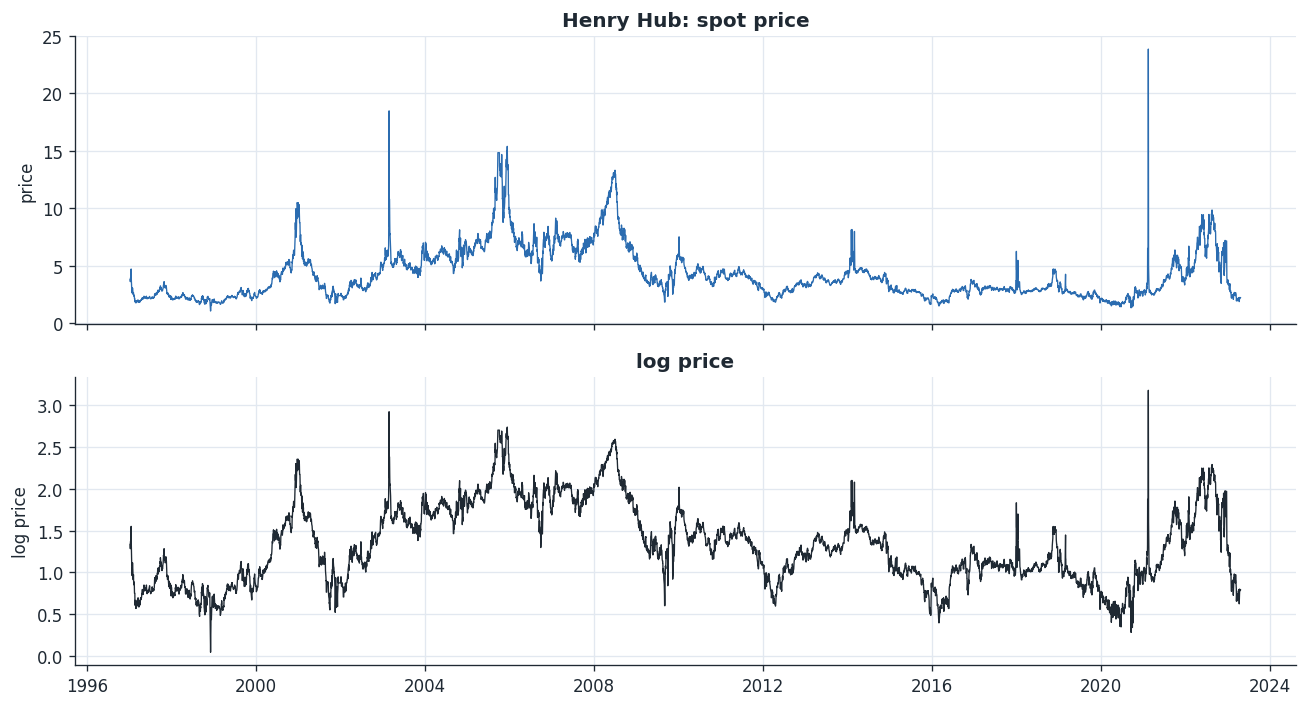

In [3]:
plots.plot_price_history(ps);

## 2. Order of integration

Two tests with opposite nulls — ADF (H0: unit root) and KPSS (H0: stationary). Prices are I(1); returns are I(0), so we model returns.

In [4]:
diagnostics.stationarity_table(ps)

,series,ADF stat,ADF p,KPSS stat,KPSS p,verdict
0,log price,-2.8570,0.0505,1.6240,0.0100,non-stationary I(1)
1,log return,-16.8440,0.0000,0.0370,0.1000,stationary I(0)


## 3. Volatility clustering (ARCH effects)

Ljung–Box on squared returns and Engle's ARCH-LM test, plus the unconditional moments that justify Student-t errors.

In [5]:
diagnostics.arch_effects(ps.ret)

,test,statistic,p_value
0,Ljung-Box Q(10) on squared returns,"3,920.3000",0.0000
1,Engle ARCH-LM(10),"2,472.6000",0.0000
2,excess kurtosis (unconditional),50.8800,NaN
3,skewness (unconditional),-0.1730,NaN


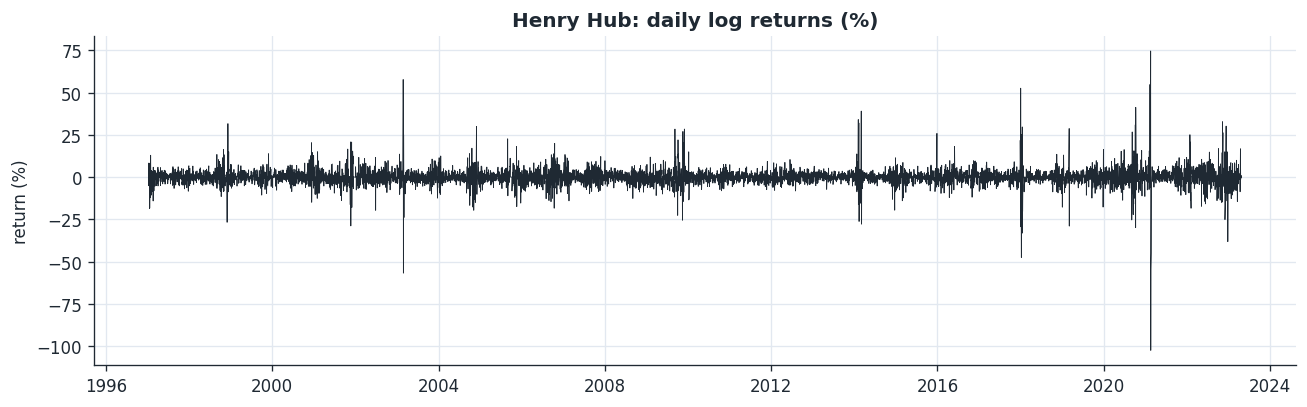

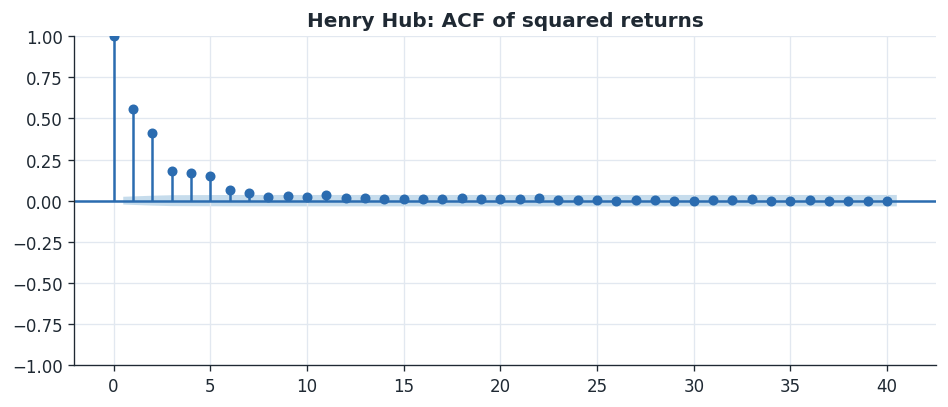

In [6]:
plots.plot_returns(ps);
plots.plot_acf_squared(ps);

## 4. The GARCH family

GARCH, GJR-GARCH and EGARCH, all with Student-t innovations. EGARCH wins on AIC. Note the GJR asymmetry term `gamma[1]` — near zero, *not* the positive equity-style leverage effect.

In [7]:
fits = volatility.fit_all(ps.ret)
volatility.comparison_table(fits)

,model,log_lik,n_params,AIC,BIC,selected
0,"EGARCH(1,1)","-18,395.1000",6,"36,802.2000","36,843.2000",<= best AIC
1,"GARCH(1,1)","-18,427.0000",5,"36,863.9000","36,898.1000",
2,"GJR-GARCH(1,1)","-18,426.8000",6,"36,865.6000","36,906.6000",


In [8]:
gjr = fits["GJR-GARCH(1,1)"]
print(f"persistence (a+b+g/2): {volatility.persistence(gjr):.4f}")
print(f"asymmetry gamma:       {gjr.params['gamma[1]']:.4f}")
gjr.params.round(4)

persistence (a+b+g/2): 0.9769
asymmetry gamma:       -0.0139


mu         -0.0055
omega       0.7911
alpha[1]    0.1864
gamma[1]   -0.0139
beta[1]     0.7974
nu          4.0998
Name: params, dtype: float64

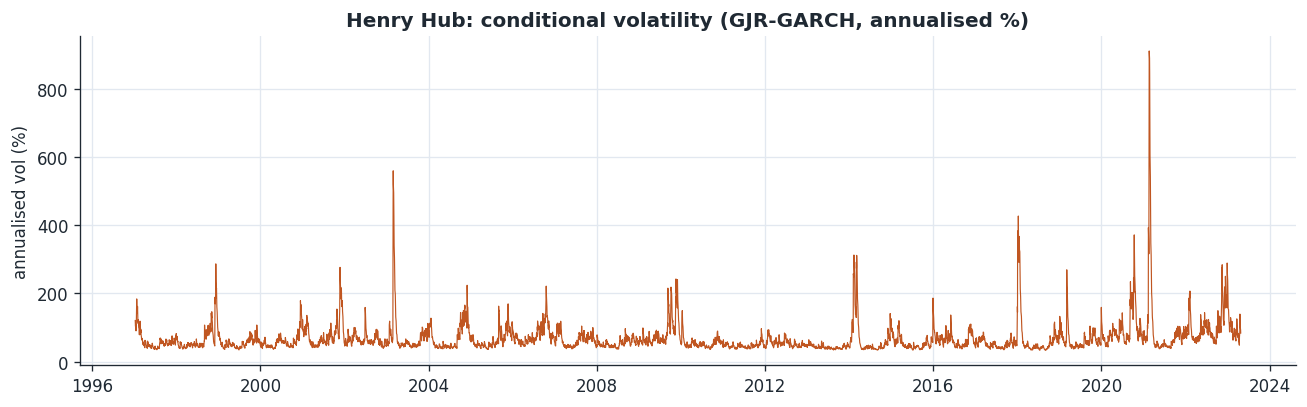

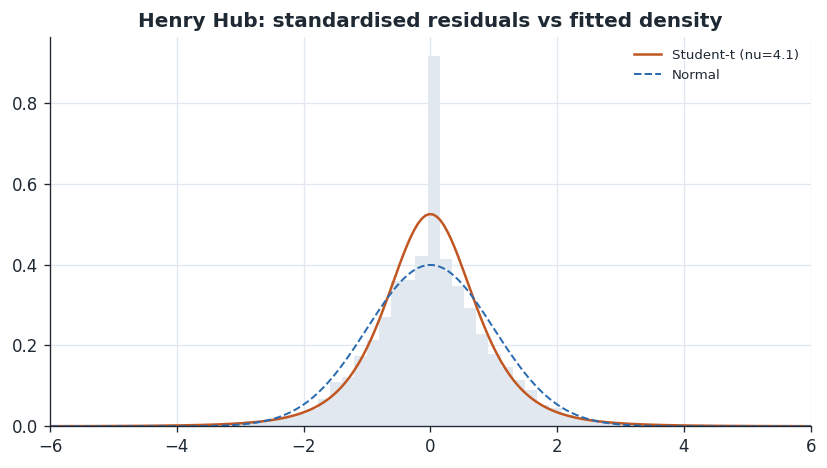

In [9]:
plots.plot_conditional_volatility(ps, gjr, "GJR-GARCH");
plots.plot_return_distribution(ps, gjr);

## 5. Out-of-sample validation

Expanding-window one-step-ahead variance forecasts over the last 500 days, scored with QLIKE and MSE. EGARCH wins out of sample too, so the in-sample preference is not over-fitting.

In [10]:
rows = []
for spec in volatility.SPECS:
    _, ev = volatility.rolling_forecast_eval(ps.ret, spec=spec, test_size=500, refit_every=25)
    rows.append({"model": ev.spec, "QLIKE": ev.qlike, "MSE": ev.mse})
pd.DataFrame(rows).sort_values("QLIKE").reset_index(drop=True)

,model,QLIKE,MSE
0,"EGARCH(1,1)",4.5527,"12,448.5000"
1,"GARCH(1,1)",4.5572,"12,577.5700"
2,"GJR-GARCH(1,1)",4.5629,"12,557.5700"


## 6. Regime switching

A two-state Markov-switching model separates a calm regime from a short, violent crisis regime. The smoothed crisis probability recovers the known stress episodes (2000–01, 2005, 2008–09, 2021–22).

In [11]:
rm = regime.fit_regimes(ps.ret, k_regimes=2)
rm.summary_frame()

,regime,daily_vol_%,annual_vol_%,stay_prob,expected_duration_days
0,calm,2.8700,45.5000,0.9770,43.2000
1,crisis,11.8300,187.8000,0.8550,6.9000


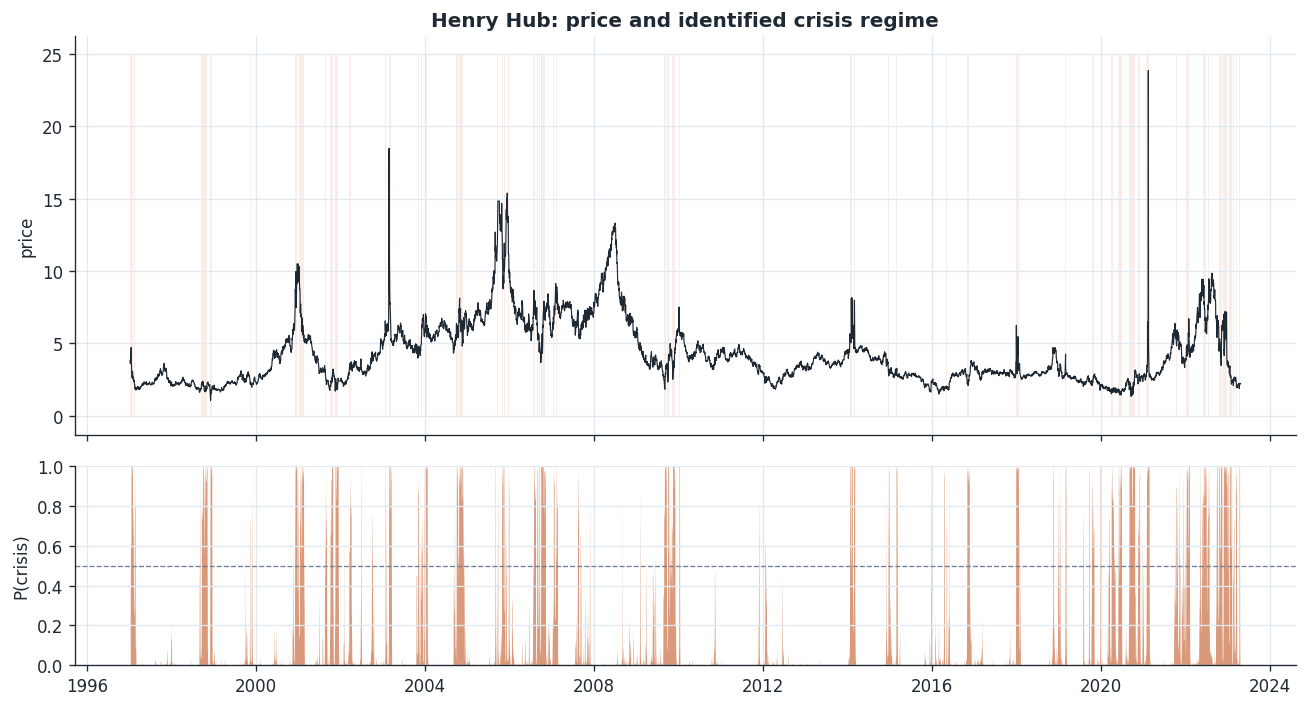

In [12]:
plots.plot_regimes(ps, rm);

In [13]:
regime.crisis_episodes(rm, threshold=0.5, min_days=10).head(10)

,start,end,trading_days
0,1997-01-10,1997-02-04,18
1,1998-09-16,1998-11-04,36
2,1998-11-30,1998-12-14,11
3,2000-12-01,2000-12-21,15
4,2001-01-11,2001-02-16,27
5,2001-10-03,2001-10-25,17
6,2001-11-14,2001-12-12,21
7,2002-03-15,2002-04-02,13
8,2003-02-21,2003-03-14,16
9,2004-01-05,2004-01-20,12


## 7. Value-at-Risk and Expected Shortfall

One-day VaR/ES from the GJR-GARCH-t model, backtested with Kupiec (coverage) and Christoffersen (independence). Passes at both 5% and 1%.

In [14]:
risk.backtest_table(ps.ret, gjr, levels=(0.05, 0.01))

,level,expected,observed,breach_rate,kupiec_p,christoffersen_cc_p,pass_5pct
0,5%,343.0000,358,5.22%,0.4092,0.6098,yes
1,1%,68.6000,55,0.80%,0.0874,0.1488,yes


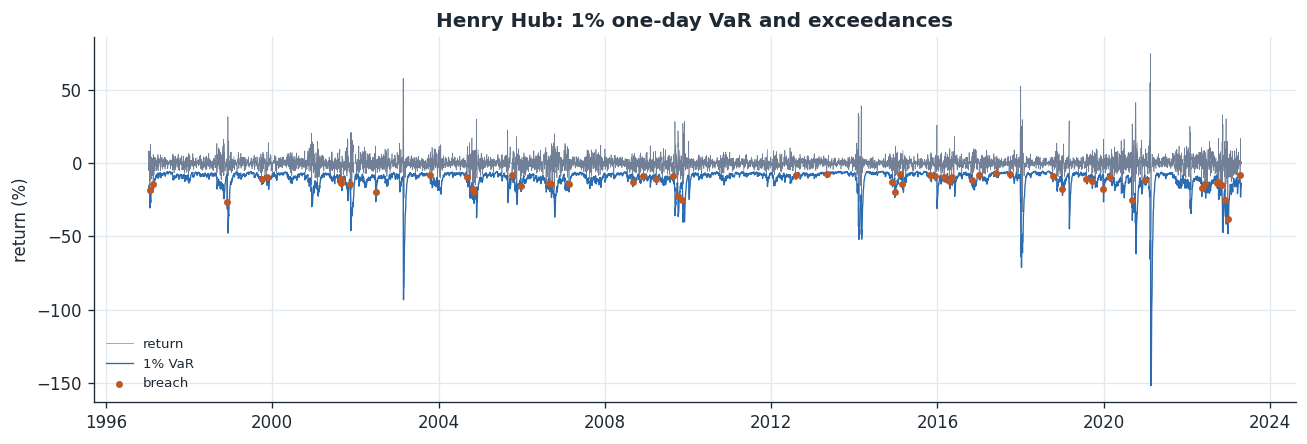

In [15]:
var_path = risk.value_at_risk(gjr, alpha=0.01)["VaR"]
plots.plot_var_backtest(ps, gjr, var_path, 0.01);

## 8. Seasonality

Natural gas volatility peaks in winter (February ~152% annualised) and troughs in summer. The seasonal dummy regression rejects the no-seasonality null decisively.

,month,annual_vol_%,annual_mean_%,n_obs
0,Jan,95.3000,-43.2000,592
1,Feb,152.2000,-74.8000,544
2,Mar,69.2000,6.9000,599
3,Apr,46.2000,29.2000,575
4,May,47.9000,40.5000,574
5,Jun,55.9000,-3.5000,558
6,Jul,45.2000,-7.9000,576
7,Aug,52.3000,-21.7000,575
8,Sep,72.2000,4.1000,558
9,Oct,89.5000,60.1000,575


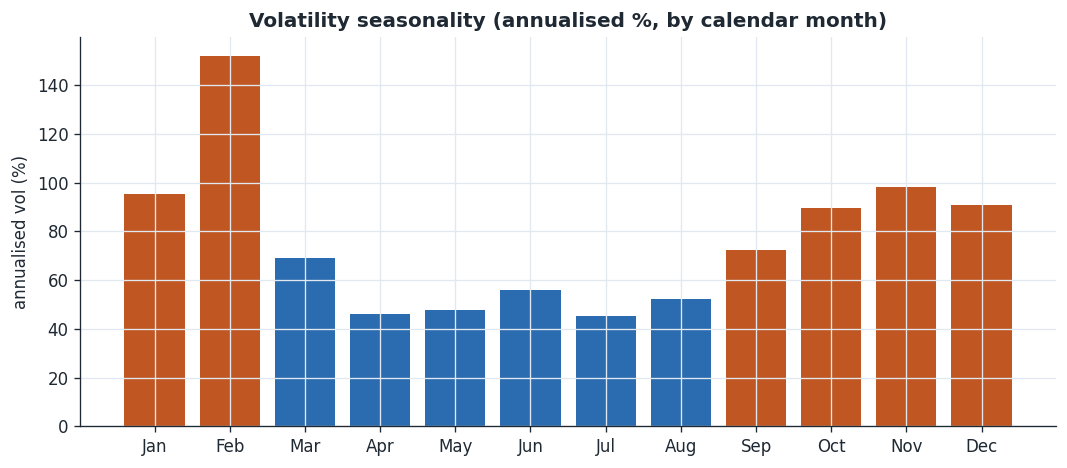

In [16]:
monthly = seasonality.monthly_volatility(ps.ret)
plots.plot_seasonality(monthly);
monthly

In [17]:
reg = seasonality.seasonal_regression(ps.ret)
print(f"joint F-test p-value: {reg.attrs['f_pvalue']:.2e}")
reg

joint F-test p-value: 5.77e-12


,term,coef,t_HAC,p_value
0,const,35.9710,3.8500,0.0001
1,month_Feb,55.8250,1.2200,0.2232
2,month_Mar,-17.0080,-1.5900,0.1111
3,month_Apr,-27.5030,-2.9300,0.0034
4,month_May,-26.8530,-2.8500,0.0043
5,month_Jun,-23.5760,-2.4800,0.0131
6,month_Jul,-27.8920,-2.9700,0.0029
7,month_Aug,-25.1230,-2.6600,0.0077
8,month_Sep,-15.3270,-1.5200,0.1273
9,month_Oct,-4.1810,-0.3700,0.7111


## Summary

- Henry Hub returns are stationary, fat-tailed (excess kurtosis ≈ 51) and strongly clustered.
- **EGARCH(1,1)-t** is the best volatility model in and out of sample; volatility persistence ≈ 0.98.
- The leverage asymmetry that dominates equities is **absent** in gas — a commodity-specific result.
- A Markov-switching model cleanly separates calm (~46% vol) and crisis (~188% vol) regimes and dates the historical episodes.
- The resulting 1-day VaR passes Kupiec and Christoffersen at 5% and 1%.
- Gas volatility is sharply seasonal (Feb ≈ 152% vs summer ≈ 45%).

Swap in `data.fetch_fred("brent")` to rerun the entire analysis on crude.